# CSE 4095 — Class 5 v3
## Feature Engineering → Importance → Selection → Randomized Search
Protect the final test set throughout model development.

## 1. Load and inspect Auto MPG

Shape: (398, 7)


,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
0,18.0,8,307.0,130.0,3504,12.0,70
1,15.0,8,350.0,165.0,3693,11.5,70
2,18.0,8,318.0,150.0,3436,11.0,70
3,16.0,8,304.0,150.0,3433,12.0,70
4,17.0,8,302.0,140.0,3449,10.5,70


Columns: ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'model-year']

Data types:
mpg             float64
cylinders         int64
displacement    float64
horsepower      float64
weight            int64
acceleration    float64
model-year        int64
dtype: object

Missing values:
mpg             0
cylinders       0
displacement    0
horsepower      2
weight          0
acceleration    0
model-year      0
dtype: int64


,mpg,cylinders,displacement,horsepower,weight,acceleration,model-year
count,398.000000,398.000000,398.000000,396.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.189394,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.402030,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,92.000000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,125.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000



MPG summary:
count    398.000000
mean      23.514573
std        7.815984
min        9.000000
25%       17.500000
50%       23.000000
75%       29.000000
max       46.600000
Name: mpg, dtype: float64


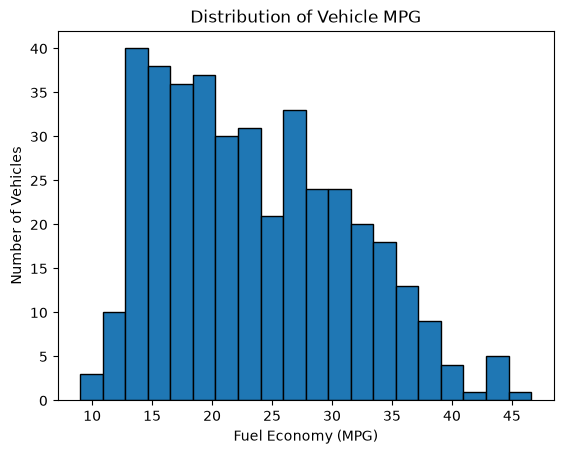

In [205]:
# TODO: load GitHub CSV; inspect shape, types, missing values, mpg
import pandas as pd
import matplotlib.pyplot as plt

# Load the GitHub CSV
url = "https://raw.githubusercontent.com/plotly/datasets/master/auto-mpg.csv"
df = pd.read_csv(url, na_values=["?"])

# Inspect shape, first rows, column names, and data types
print("Shape:", df.shape)
display(df.head())
print("Columns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)

# Inspect missing values and descriptive statistics
print("\nMissing values:")
print(df.isna().sum())
display(df.describe(include="all"))

# Inspect the prediction target: miles per gallon
print("\nMPG summary:")
print(df["mpg"].describe())

df["mpg"].plot.hist(bins=20, edgecolor="black")
plt.title("Distribution of Vehicle MPG")
plt.xlabel("Fuel Economy (MPG)")
plt.ylabel("Number of Vehicles")
plt.show()

1. What does one row represent? 
- One row represents a vehicle observation with its characteristics and fuel economy.

2. What is the prediction target? 
- The target is mpg, the vehicle’s fuel economy in miles per gallon.

3. Why is this a regression problem? 
- MPG is a numerical quantity, so the goal is to predict a number rather than a category.

4. Which columns could potentially be useful predictors? 
- Potential predictors include cylinders, displacement, horsepower, weight, acceleration, model year, and origin, if present. These describe the vehicle’s engine, size, performance, age, and manufacturing region. Confirm the actual column names before selecting them, and exclude mpg from the inputs.

5. Which columns contain missing values? 

Missing values:
- mpg             0
- cylinders       0
- displacement    0
- horsepower      2
- weight          0
- acceleration    0
- model-year      0

## 2. Define X/y and create one train/test split
Use `random_state=42`. Keep the split fixed.

In [206]:
# TODO: X, y, train_test_split

from sklearn.model_selection import train_test_split

# Separate predictors from the target
X = df.drop(columns=["mpg"])
y = df["mpg"]

# Reserve 20% for final evaluation
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

Training shape: (318, 6)
Test shape: (80, 6)


1. Why create the test set before experimenting? 
- Creating it first reserves independent data for evaluating the completed workflow. Development decisions can then be made using only training data and cross-validation.
2. Why not repeatedly check test MAE while creating features? 
- Repeated checks allow test results to influence our decisions. The test set then becomes part of model development and no longer provides an independent final evaluation.

3. What happens if we keep modifying the model until test performance improves? 
- We may fit our decisions to accidental patterns in that particular test set. Its score can become overly optimistic and may not reflect performance on new vehicles.

## 3. Mean baseline + untuned Random Forest baseline

In [207]:
# TODO: baseline metrics and training-data CV
import numpy as np
import pandas as pd

from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline

# Use only the original numerical predictors
X_train_numeric = X_train.select_dtypes(include="number")

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "mae": "neg_mean_absolute_error",
    "mse": "neg_mean_squared_error",
    "r2": "r2"
}

# Baseline 1: predict the mean of the training observations
mean_baseline = DummyRegressor(strategy="mean")

# Baseline 2: untuned Random Forest
rf_baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(random_state=42))
])

results = []

for name, model in [
    ("Mean predictor", mean_baseline),
    ("Untuned Random Forest", rf_baseline)
]:
    scores = cross_validate(
        model,
        X_train_numeric,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    fold_mae = -scores["test_mae"]
    fold_rmse = np.sqrt(-scores["test_mse"])

    results.append({
        "Model": name,
        "Mean CV MAE": fold_mae.mean(),
        "CV MAE Std.": fold_mae.std(),
        "Mean CV RMSE": fold_rmse.mean(),
        "Mean CV R²": scores["test_r2"].mean()
    })

baseline_results = pd.DataFrame(results)
display(baseline_results.round(3))

# Fit on all training data for later use
mean_baseline.fit(X_train_numeric, y_train)
rf_baseline.fit(X_train_numeric, y_train)

print(f"Full training-set mean MPG: {y_train.mean():.3f}")

,Model,Mean CV MAE,CV MAE Std.,Mean CV RMSE,Mean CV R²
0,Mean predictor,6.702,0.452,7.923,-0.017
1,Untuned Random Forest,2.002,0.131,2.918,0.859


Full training-set mean MPG: 23.608


1. What does the mean predictor accomplish? 
- It provides a simple reference by predicting the training-set mean MPG for every vehicle. A useful model should improve on this reference by learning relationships between vehicle characteristics and MPG.

2. How does the untuned Random Forest compare with the simple baseline? 
- The mean predictor's Mean CV MAE was 6.702 while the untuned Random Forest's was 2.002. The Random Forest improves on Mean CV MAE by having approximately 4.7 lower Mean CV MAE

3. Why establish a model baseline before improving the features? 
- The untuned forest shows how well the original features work. Keeping the model settings and CV folds fixed lets us assess whether engineered features improve performance.

## 4. Initial feature engineering
Ask AI for candidates first. Choose 2–4 with a rationale before evaluating them.

In [208]:
# TODO: create selected engineered features safely
# Create the two engineered features using training data only
X_train_engineered = X_train_numeric.copy()

X_train_engineered["horsepower_per_displacement"] = (
    X_train_engineered["horsepower"]
    / X_train_engineered["displacement"].replace(0, np.nan)
)

X_train_engineered["power_to_weight"] = (
    X_train_engineered["horsepower"]
    / X_train_engineered["weight"].replace(0, np.nan)
)

# Compare feature sets using the same untuned model and CV folds
feature_results = []

for name, features in [
    ("Original", X_train_numeric),
    ("Original + two engineered features", X_train_engineered)
]:
    scores = cross_validate(
        rf_baseline,
        features,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    fold_mae = -scores["test_score"]

    feature_results.append({
        "Feature Set": name,
        "# Features": features.shape[1],
        "Mean CV MAE": fold_mae.mean(),
        "CV Std.": fold_mae.std()
    })

feature_comparison = pd.DataFrame(feature_results)
display(feature_comparison.round(3))

original_mae = feature_comparison.loc[0, "Mean CV MAE"]
engineered_mae = feature_comparison.loc[1, "Mean CV MAE"]
improvement = original_mae - engineered_mae

print(f"MAE improvement: {improvement:.4f} MPG")
print("Positive = lower error with engineered features.")

,Feature Set,# Features,Mean CV MAE,CV Std.
0,Original,6,2.002,0.131
1,Original + two engineered features,8,1.998,0.103


MAE improvement: 0.0036 MPG
Positive = lower error with engineered features.


1. horsepower_per_displacement

Formula -> horserpower_per_displacement = horsepower / displacement

- This feature represents the amount of horsepower produced relative to engine displacement, or engine size. Two vehicles with similarly sized engines may produce different amounts of power. This ratio could help the model capture differences in engine characteristics associated with MPG. However, it does not directly measure fuel efficiency, so cross-validation is needed to determine whether it improves predictions

2. power_to_weight

Formula -> power_to_weight = horsepower / weight

- This feature represents engine power relative to vehicle weight. Two vehicles with similar horsepower may have different fuel-economy patterns if one is much heavier. Combining horsepower and weight into a ratio may make this relationship easier for the model to use when predicting MPG. Cross-validation is needed to determine whether it adds useful information beyond the original features.

3. displacement_per_cylinder

Formula -> displacement_per_cylinder = displacement / cylinders

- This feature represents the average engine displacement per cylinder. Two engines with the same total displacement may have different numbers of cylinders, resulting in different cylinder sizes. This ratio may capture engine-design differences associated with MPG. It does not directly measure fuel efficiency, so cross-validation is needed to determine whether it improves predictions beyond the original features.

## 5. Original vs. engineered representation
Keep Random Forest settings and CV procedure fixed.

In [209]:
# TODO: compare CV MAE for original vs engineered features
from sklearn.model_selection import cross_val_score

# Original numerical features
X_original = X_train_numeric.copy()

# Original + all three engineered features
X_train_engineered = X_original.copy()

X_train_engineered["horsepower_per_displacement"] = (
    X_original["horsepower"]
    / X_original["displacement"].replace(0, np.nan)
)

X_train_engineered["power_to_weight"] = (
    X_original["horsepower"]
    / X_original["weight"].replace(0, np.nan)
)

X_train_engineered["displacement_per_cylinder"] = (
    X_original["displacement"]
    / X_original["cylinders"].replace(0, np.nan)
)

# Reuse identical folds for both models
cv_splits = list(cv.split(X_original, y_train))

comparison_rows = []

for name, features in [
    ("Original", X_original),
    ("Original + Engineered", X_train_engineered)
]:
    scores = cross_val_score(
        rf_baseline,  # Median imputation + untuned Random Forest
        features,
        y_train,
        cv=cv_splits,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    fold_mae = -scores

    comparison_rows.append({
        "Feature Set": name,
        "Mean CV MAE": fold_mae.mean(),
        "CV Std.": fold_mae.std()
    })

feature_comparison = pd.DataFrame(comparison_rows)
display(feature_comparison.round(3))

improvement = (
    feature_comparison.loc[0, "Mean CV MAE"]
    - feature_comparison.loc[1, "Mean CV MAE"]
)

print(f"MAE improvement from engineered features: {improvement:.4f} MPG")

,Feature Set,Mean CV MAE,CV Std.
0,Original,2.002,0.131
1,Original + Engineered,2.003,0.087


MAE improvement from engineered features: -0.0012 MPG


1. Did feature engineering improve CV performance? 
- The original performed better

2. Was the improvement large? 
- The "improvement" was pretty miniscule, exactly one thousandth of an improvement

3. Did all engineered features necessarily help?  
- No. An engineered feature might be redundant or unhelpful. Comparing the two complete feature sets cannot establish whether each added feature helped individually; that would require controlled comparisons that add or remove individual features.

4. If performance became worse, did the experiment fail? 
- No. A controlled experiment is useful when it shows that a proposed change did not help. That evidence can justify keeping the simpler original feature set.

## 6. Built-in Random Forest feature importance
Fit the candidate representation, obtain feature names, create a sorted table and plot.

,Feature,Importance
0,displacement,0.4131
1,horsepower,0.1677
2,weight,0.1226
3,cylinders,0.1176
4,model-year,0.1011
5,displacement_per_cylinder,0.0253
6,acceleration,0.0205
7,power_to_weight,0.0164
8,horsepower_per_displacement,0.0157


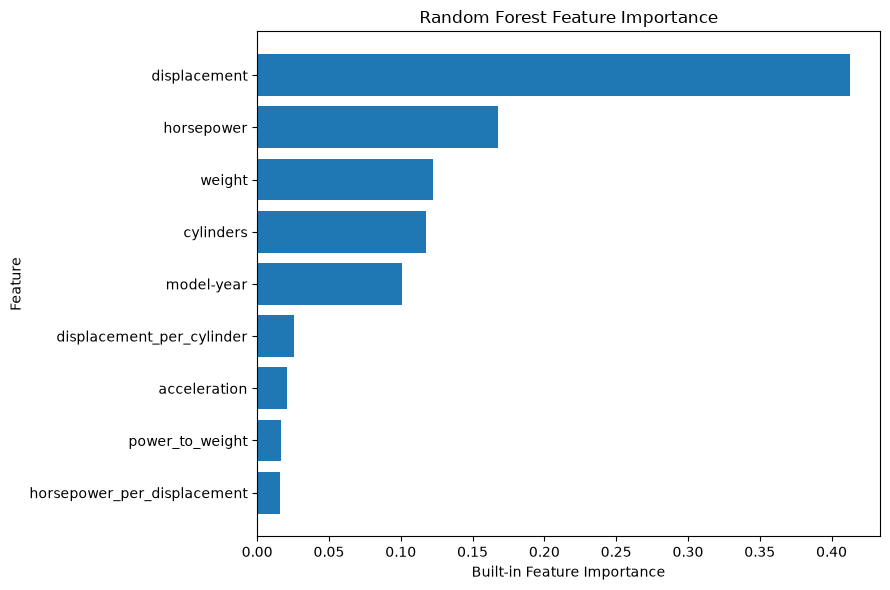

In [210]:
# TODO: feature_importances_ + feature names + horizontal bar plot
from sklearn.base import clone
import matplotlib.pyplot as plt

# Fit a separate model using original + engineered features
rf_engineered = clone(rf_baseline)
rf_engineered.fit(X_train_engineered, y_train)

# Extract importance scores from the Random Forest in the pipeline
importance_table = pd.DataFrame({
    "Feature": X_train_engineered.columns,
    "Importance": rf_engineered.named_steps["model"].feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_table.reset_index(drop=True).round(4))

# Plot with the most important feature at the top
plot_data = importance_table.sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(plot_data["Feature"], plot_data["Importance"])
plt.xlabel("Built-in Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

1. Which features appear most important?
- displacement, horsepower, and weight are in the top 3

2. Which appear least important?
- horsepower_per_displacement

3. Are any engineered features highly ranked?
- None of my engineered features were highly ranked

4. Did any result surprise you?
- I was surprised none of my engineered features were of much importance

## 7. Permutation importance
Use validation/training evidence, not the final test set.

,Feature,Mean MAE Increase,Std.
0,model-year,1.5847,0.3476
1,displacement,1.1115,0.3567
2,weight,1.0281,0.1819
3,horsepower,0.9617,0.3123
4,cylinders,0.2854,0.2305
5,displacement_per_cylinder,0.1203,0.0703
6,acceleration,0.0751,0.0624
7,horsepower_per_displacement,0.0422,0.0561
8,power_to_weight,0.0135,0.0511


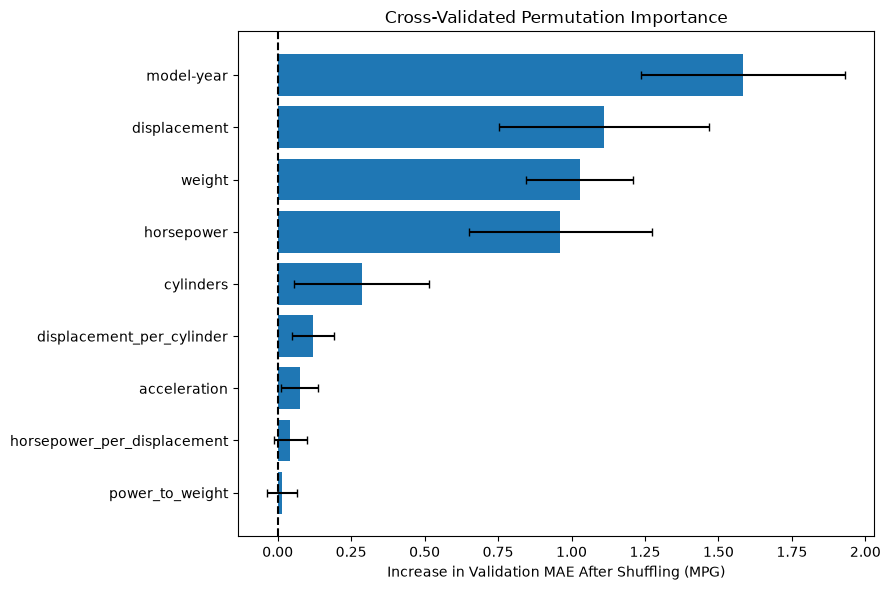

In [211]:
# TODO: permutation_importance
from sklearn.inspection import permutation_importance
from sklearn.base import clone

fold_importances = []

for train_idx, valid_idx in cv_splits:
    X_fold_train = X_train_engineered.iloc[train_idx]
    X_fold_valid = X_train_engineered.iloc[valid_idx]
    y_fold_train = y_train.iloc[train_idx]
    y_fold_valid = y_train.iloc[valid_idx]

    model = clone(rf_baseline)
    model.fit(X_fold_train, y_fold_train)

    result = permutation_importance(
        model,
        X_fold_valid,
        y_fold_valid,
        scoring="neg_mean_absolute_error",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    fold_importances.append(result.importances)

# Combine results across folds and shuffle repetitions
all_importances = np.concatenate(fold_importances, axis=1)

permutation_table = pd.DataFrame({
    "Feature": X_train_engineered.columns,
    "Mean MAE Increase": all_importances.mean(axis=1),
    "Std.": all_importances.std(axis=1)
}).sort_values("Mean MAE Increase", ascending=False)

display(permutation_table.reset_index(drop=True).round(4))

plot_data = permutation_table.sort_values("Mean MAE Increase")

plt.figure(figsize=(9, 6))
plt.barh(
    plot_data["Feature"],
    plot_data["Mean MAE Increase"],
    xerr=plot_data["Std."],
    capsize=3
)
plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Increase in Validation MAE After Shuffling (MPG)")
plt.title("Cross-Validated Permutation Importance")
plt.tight_layout()
plt.show()

1. Which features have the highest permutation importance? 
- Model-year

2. Which have low permutation importance? 
- power_to_weight

3. Does the ranking agree with built-in importance? 
- For the most part yes, having the engineered features ranking lower, but model_year wasn't previously inside the built-in importance chart

4. Why might the methods disagree? 
- Built-in importance measures how much features reduce impurity during tree training. Permutation importance measures how much a fitted model’s performance changes when a feature is shuffled. They measure different things. Built-in importance can favor features with many possible split points, while correlated features can substitute for each other and reduce the apparent permutation importance of either one. The evaluation data and sampling variability can also affect rankings.

## 8. Compare importance rankings
Discuss engineered features, correlated predictors, and limitations.

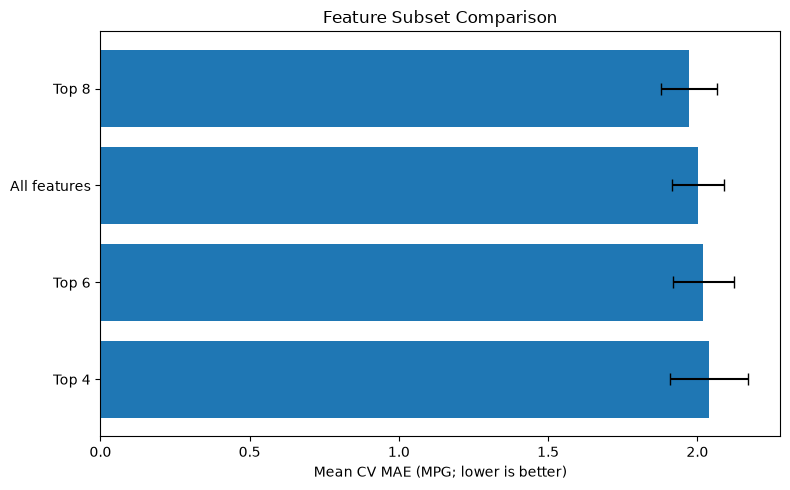

In [212]:
# TODO: optional comparison table or plot
# Plot the candidate feature sets with CV standard-deviation error bars
plot_data = selection_comparison.sort_values("Mean CV MAE")

plt.figure(figsize=(8, 5))
plt.barh(
    plot_data["Feature Set"],
    plot_data["Mean CV MAE"],
    xerr=plot_data["CV Std."],
    capsize=4
)
plt.gca().invert_yaxis()
plt.xlabel("Mean CV MAE (MPG; lower is better)")
plt.title("Feature Subset Comparison")
plt.tight_layout()
plt.show()

1. Why can a useful feature receive low importance? 
- If another feature contains similar information, the model may rely on that other feature instead. Built-in importance may be divided between them, and shuffling one may have little effect because the other still provides useful information. Low importance does not automatically mean a feature is useless.

2. Why does importance not imply causation? 
- Importance describes how a model uses a feature to predict MPG. It does not demonstrate that changing the feature would cause MPG to change. Correlations, other vehicle characteristics, and the way the data were collected can explain predictive relationships.

## 9. Feature-selection experiment
Create candidate subsets from the importance evidence. Compare with the same CV procedure.

In [213]:
# TODO: all features vs reduced subsets; compare CV MAE and variability
# Rank features using the previous permutation-importance results
ranked_features = permutation_table["Feature"].tolist()

candidate_subsets = {
    "All features": X_train_engineered.columns.tolist(),
    "Top 8": ranked_features[:8],
    "Top 6": ranked_features[:6],
    "Top 4": ranked_features[:4]
}

selection_rows = []

for name, columns in candidate_subsets.items():
    scores = cross_val_score(
        rf_baseline,
        X_train_engineered[columns],
        y_train,
        cv=cv_splits,  # Same five folds used previously
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    fold_mae = -scores

    selection_rows.append({
        "Feature Set": name,
        "# Features": len(columns),
        "Mean CV MAE": fold_mae.mean(),
        "CV Std.": fold_mae.std()
    })

selection_comparison = pd.DataFrame(selection_rows)
display(
    selection_comparison
    .sort_values("Mean CV MAE")
    .reset_index(drop=True)
    .round(3)
)

# Show exactly which features each candidate includes
for name, columns in candidate_subsets.items():
    print(f"{name}: {', '.join(columns)}")

,Feature Set,# Features,Mean CV MAE,CV Std.
0,Top 8,8,1.972,0.094
1,All features,9,2.003,0.087
2,Top 6,6,2.020,0.103
3,Top 4,4,2.038,0.131


All features: cylinders, displacement, horsepower, weight, acceleration, model-year, horsepower_per_displacement, power_to_weight, displacement_per_cylinder
Top 8: model-year, displacement, weight, horsepower, cylinders, displacement_per_cylinder, acceleration, horsepower_per_displacement
Top 6: model-year, displacement, weight, horsepower, cylinders, displacement_per_cylinder
Top 4: model-year, displacement, weight, horsepower


1. Which feature set performs best? 
- The top 8 features performed the best

2. Can features be removed without noticeably hurting performance? 
- Reduced features hurt performed, but not by a huge noticeable amount

3. Does the smallest feature set perform best? 
- The smallest feature performed the worst, but again, not by a huge margin

4. If two sets perform almost identically, which would you choose and why? 
- I would generally choose the smaller, simpler set if its CV performance and stability were comparable. It requires fewer inputs and makes the workflow easier to maintain. I would also consider whether the features are reliable and available when predicting new vehicles.

Feature engineering comes first because a raw input that appears weak on its own might still help create a useful feature. Removing it too early limits the relationships we can investigate. We then examine importance and test candidate subsets using CV.

I would choose the Top 8 feature set for hyperparameter tuning, the top 8 has the lowest CV MAE, approximately 1.97 MPG, with variability simlar to the all-feature model. It uses fewer predictors while slightly reducing average error. The Top 6 and Top 4 subsets are simpler but their mean errors are slightly higher

The differences are small and the standard-deviation bars overlap, so this does not demonstrate a substantial improvement. Top 8 offers a reasonable balance of accuracy, consistency, and simplicity. This decision uses only training-data cross-validation.

## 10. Optional engineering/selection iteration
Make at most one small follow-up change if the importance results motivate a specific question.

In [214]:
# TODO: optional targeted experiment

print("N/A")

N/A


1. What is a hyperparameter? 
- A hyperparameter is a setting that controls how a model is trained or structured, such as a tree’s maximum depth or the number of trees in a forest.

2. How does it differ from a learned parameter? 
- We set hyperparameters before a particular training run. Training learns model details from data, such as a tree’s split features, split thresholds, and leaf predictions.

3. What does RandomizedSearchCV do? 
- It samples a specified number of hyperparameter combinations, evaluates each using CV, and identifies the combination with the best mean score among those tested. With refitting enabled, it then fits that combination on all the data supplied to the search.

4. Why prefer it to manually trying combinations? 
- It organizes comparisons consistently and explores several settings together with a controlled computational budget. It reduces the bookkeeping required for manually training and comparing many models.

5. How does it differ from GridSearchCV? 
- Grid search evaluates every combination in a specified grid. Randomized search samples a limited number of combinations from lists or distributions, which can explore a larger search space with fewer evaluations. It does not guarantee that it will find the best possible settings.

n_estimators controls how many trees make up the forest. Predictions are averaged across those trees. Increasing the number usually makes predictions more stable, but takes more time and memory. It does not make each individual tree more complex. My search selected 300 trees.
max_depth limits how many levels each tree can grow. Deeper trees can learn more detailed relationships, but may also fit noise in the training data. Shallower trees are simpler and can underfit. My search selected a maximum depth of 10.
min_samples_split controls how many observations a node must contain before the model can consider splitting it. Increasing this value prevents splits in small groups and generally produces simpler trees. My search selected 2, allowing small nodes to split when other conditions permit.
min_samples_leaf sets the minimum number of training observations that must remain in each leaf. A leaf produces a prediction by averaging its observations’ MPG values. Larger minimums make predictions smoother and less sensitive to individual vehicles, but may miss detailed patterns. My search selected 1.
max_features controls how many features are considered when choosing each split. Considering fewer features can make the trees more diverse, but may exclude a useful predictor from a particular split. Considering more features gives each split more choices, though trees may become more similar. My search selected 1.0, meaning all eight selected features are considered at every split.

## 11. RandomizedSearchCV
Freeze the feature representation first; tune Random Forest on training data only.

In [215]:
# TODO: distributions + RandomizedSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone

# Freeze the selected feature representation before tuning
selected_features = candidate_subsets["Top 8"].copy()
X_train_selected = X_train_engineered[selected_features].copy()

# "model__" targets the Random Forest step in the pipeline
param_distributions = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__max_features": [0.5, 0.75, 1.0],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator=clone(rf_baseline),
    param_distributions=param_distributions,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=cv_splits,
    random_state=42,
    n_jobs=-1,
    refit=True,
    return_train_score=False
)

random_search.fit(X_train_selected, y_train)

print("Best hyperparameters:")
print(random_search.best_params_)
print(f"\nBest mean CV MAE: {-random_search.best_score_:.4f} MPG")

# Already refitted on all training data with the selected features
best_model = random_search.best_estimator_

Best hyperparameters:
{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': 10}

Best mean CV MAE: 1.9771 MPG


1. Which combination performed best?
- The combination listed above had the lowest mean CV MAE among the 25 sampled combinations.

2. Were several combinations very similar?
- Check the table before concluding. Differences of only a few hundredths of MPG would suggest similar average performance, especially relative to fold variability.

3. Did any best value occur at a search boundary?
- Yes: n_estimators=300 was the largest tree count; min_samples_split=2 and min_samples_leaf=1 were the smallest values; and max_features=1.0 used the maximum possible feature fraction. Depth 10 was inside the searched range.

4. What might that suggest?
A future controlled experiment could investigate whether more than 300 trees provides enough improvement to justify extra computation. The minimum split and leaf sizes suggest stronger restrictions were less successful in the sampled configurations, but their effects depend on the other settings. Boundary values alone do not justify another search; first examine how close the leading scores are.

## 12. Inspect search results
Show best parameters, best CV MAE, and top configurations.

In [216]:
stage_comparison = pd.DataFrame({
    "Stage": [
        "Baseline Random Forest",
        "Feature Engineering",
        "Feature Selection",
        "Randomized Search"
    ],
    "Feature Set": [
        "Original",
        "Original + Engineered",
        "Top 8",
        "Top 8"
    ],
    "CV MAE": [
        feature_comparison.loc[
            feature_comparison["Feature Set"] == "Original", "Mean CV MAE"
        ].iloc[0],
        feature_comparison.loc[
            feature_comparison["Feature Set"] == "Original + Engineered",
            "Mean CV MAE"
        ].iloc[0],
        selection_comparison.loc[
            selection_comparison["Feature Set"] == "Top 8", "Mean CV MAE"
        ].iloc[0],
        -random_search.best_score_
    ]
})

# Positive values indicate improvement over the previous stage
stage_comparison["MAE Improvement"] = (
    stage_comparison["CV MAE"].shift(1) - stage_comparison["CV MAE"]
)

display(stage_comparison.round(4))

,Stage,Feature Set,CV MAE,MAE Improvement
0,Baseline Random Forest,Original,2.0016,NaN
1,Feature Engineering,Original + Engineered,2.0028,-0.0012
2,Feature Selection,Top 8,1.9724,0.0304
3,Randomized Search,Top 8,1.9771,-0.0046


1. Which stage produced the largest improvement?
- Feature selection produced the largest improvement, reducing CV MAE from 2.0028 to 1.9724 MPG, an improvement of 0.0304 MPG.

2. Did feature engineering help?
- It did not improve average CV performance. MAE increased slightly from 2.0016 to 2.0028 MPG. This difference was extremely small.

3. Did feature selection help?
- Yes, slightly. The Top 8 subset achieved the lowest CV MAE while using fewer predictors than the full engineered feature set.

4. Did hyperparameter tuning help?
- No. The tuned model’s CV MAE was 1.9771 MPG, slightly higher than the untuned Top 8 model’s 1.9724 MPG. The search did not improve on the untuned configuration.

5. Was every additional step beneficial?
- No. Only feature selection reduced average CV MAE. All changes were small compared with the observed fold variability, so the results do not demonstrate a substantial performance improvement. The experiments were still useful for evaluating which changes justified their complexity.

## 13. Final held-out test evaluation
Only now evaluate the frozen workflow on the test set.

In [217]:
# TODO: MAE, RMSE, R2, actual-vs-predicted, residual plot
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Apply the same feature representation to the held-out test data
X_test_engineered = X_test[X_train_numeric.columns].copy()

X_test_engineered["horsepower_per_displacement"] = (
    X_test_engineered["horsepower"]
    / X_test_engineered["displacement"].replace(0, np.nan)
)

X_test_engineered["power_to_weight"] = (
    X_test_engineered["horsepower"]
    / X_test_engineered["weight"].replace(0, np.nan)
)

X_test_engineered["displacement_per_cylinder"] = (
    X_test_engineered["displacement"]
    / X_test_engineered["cylinders"].replace(0, np.nan)
)

# Use the same selected columns and column order
X_test_selected = X_test_engineered[selected_features]

# Predict once; retain predictions for later plots and residual analysis
y_test_pred = random_search.best_estimator_.predict(X_test_selected)

test_results = pd.DataFrame([{
    "Model": "Tuned Random Forest",
    "Test MAE": mean_absolute_error(y_test, y_test_pred),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, y_test_pred)),
    "Test R²": r2_score(y_test, y_test_pred)
}])

display(test_results.round(4))

,Model,Test MAE,Test RMSE,Test R²
0,Tuned Random Forest,1.6863,2.2265,0.9078


1. How does final test performance compare with CV performance?
- Test MAE was 1.6863 MPG, compared with CV MAE of 1.9771 MPG. Test error was approximately 0.291 MPG lower. Test RMSE was 2.2265 MPG, and test R² was 0.9078.

2. Is the result reasonably consistent with cross-validation?
- Broadly, yes. Both indicate average errors around 2 MPG, although the held-out test set produced better results. Different vehicle samples can differ in prediction difficulty.

3. Did the model substantially outperform the mean baseline?
- The high test R² suggests strong performance, but you need the mean baseline’s test metrics for a direct comparison. Use the training mean without fitting anything on the test set

4. Is there evidence that development overfit the training data?
- These results show no obvious sign of development overfitting, since test MAE was lower than CV MAE. However, one held-out split cannot prove that overfitting is absent. Keep the model fixed after this evaluation.

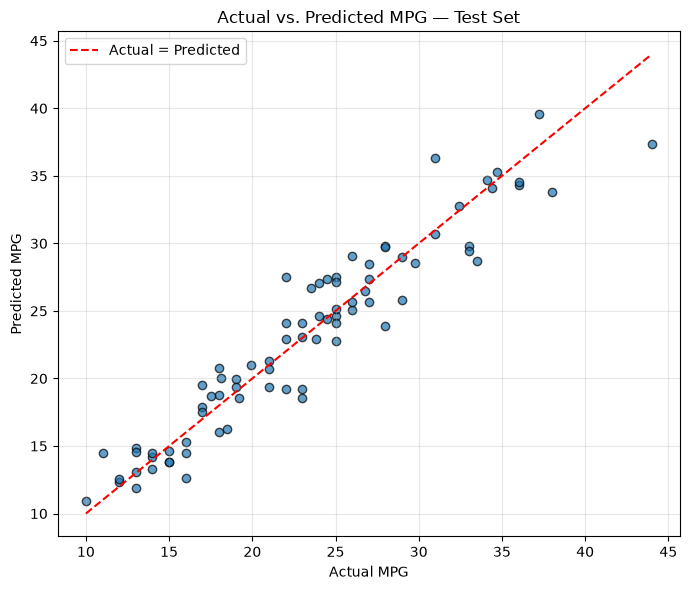

In [218]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_test_pred, alpha=0.7, edgecolors="black")

# Diagonal representing perfect predictions
lower = min(y_test.min(), y_test_pred.min())
upper = max(y_test.max(), y_test_pred.max())
plt.plot(
    [lower, upper], [lower, upper],
    color="red", linestyle="--", label="Actual = Predicted"
)

plt.xlabel("Actual MPG")
plt.ylabel("Predicted MPG")
plt.title("Actual vs. Predicted MPG — Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

1. Are predictions generally close to the diagonal?
- They are, predictions follow the line for the most part with few outliers

2. Where does the model make larger errors?
- After 40 MPG is when the model starting having larger errors

3. Does the model appear better at predictin some MPG ranges than others?
- It seem to predict MPG pretty well from 0-25, which is up to when it started to make some mistakes

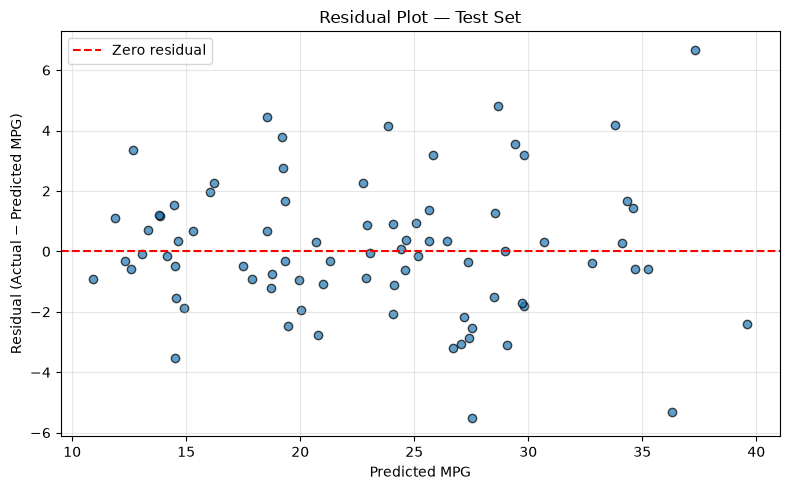

In [219]:
# Residual = actual MPG - predicted MPG
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_test_pred, residuals, alpha=0.7, edgecolors="black")
plt.axhline(0, color="red", linestyle="--", label="Zero residual")

plt.xlabel("Predicted MPG")
plt.ylabel("Residual (Actual − Predicted MPG)")
plt.title("Residual Plot — Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

1. Do residuals appear randomly distributed around zero?
- They do, its randomly placed around the scatter plot

2. Is there an obvious pattern?
- There's really isn't a clear pattern

3. Does the model systematically overpredict or underpredict in any region?
- No, there's no real clear pattern as to when it starts to overpredict or underpredict

In [220]:
# Use existing test predictions; no additional fitting
error_analysis = X_test_engineered.copy()

error_analysis["Actual MPG"] = y_test
error_analysis["Predicted MPG"] = y_test_pred
error_analysis["Residual"] = y_test - y_test_pred
error_analysis["Absolute Error"] = error_analysis["Residual"].abs()

# Keep all original and engineered predictors for context
display_columns = [
    "Actual MPG",
    "Predicted MPG",
    "Residual",
    "Absolute Error"
] + X_test_engineered.columns.tolist()

largest_errors = (
    error_analysis
    .nlargest(10, "Absolute Error")
    [display_columns]
)

display(largest_errors.round(3))

,Actual MPG,Predicted MPG,Residual,Absolute Error,cylinders,displacement,horsepower,weight,acceleration,model-year,horsepower_per_displacement,power_to_weight,displacement_per_cylinder
394,44.0,37.327,6.673,6.673,4,97.0,52.0,2130,24.6,82,0.536,0.024,24.250
389,22.0,27.517,-5.517,5.517,6,232.0,112.0,2835,14.7,82,0.483,0.040,38.667
377,31.0,36.313,-5.313,5.313,4,91.0,68.0,1970,17.6,82,0.747,0.035,22.750
238,33.5,28.680,4.820,4.820,4,98.0,83.0,2075,15.9,77,0.847,0.040,24.500
298,23.0,18.546,4.454,4.454,8,350.0,125.0,3900,17.4,79,0.357,0.032,43.750
383,38.0,33.823,4.177,4.177,4,91.0,67.0,1965,15.0,82,0.736,0.034,22.750
30,28.0,23.849,4.151,4.151,4,140.0,90.0,2264,15.5,71,0.643,0.040,35.000
101,23.0,19.218,3.782,3.782,6,198.0,95.0,2904,16.0,73,0.480,0.033,33.000
181,33.0,29.433,3.567,3.567,4,91.0,53.0,1795,17.5,75,0.582,0.030,22.750
124,11.0,14.512,-3.512,3.512,8,350.0,180.0,3664,11.0,73,0.514,0.049,43.750


Case 238 — Observation: The vehicle’s actual fuel economy was 33.5 MPG, while the model predicted 28.680 MPG. Its residual was +4.820 MPG, meaning the model underpredicted by 4.820 MPG. It had 4 cylinders, displacement of 98, horsepower of 83, and weight of 2,075.
- The model may have learned from similar vehicles with lower MPG, pulling its prediction below this vehicle’s actual 33.5 MPG. Characteristics missing from the predictors, such as transmission type or engine technology, might help explain its higher fuel economy.

Case 124 — Observation: The vehicle’s actual fuel economy was 11.0 MPG, while the model predicted 14.512 MPG. Its residual was −3.512 MPG, meaning the model overpredicted by 3.512 MPG. It had 8 cylinders, displacement of 350, horsepower of 180, and weight of 3,664.
- The model may have averaged predictions from similar vehicles with higher MPG, causing it to overpredict this vehicle’s actual 11.0 MPG. There may also have been relatively few comparable low-MPG vehicles in the training data.

I expect increasing the number of trees from 300 to 600 to slightly reduce mean CV MAE because averaging more trees may make predictions more stable.

In [221]:
experiment_rows = []

for tree_count in [300, 600]:
    model = clone(random_search.best_estimator_)
    model.set_params(model__n_estimators=tree_count)

    scores = cross_val_score(
        model,
        X_train_selected,
        y_train,
        cv=cv_splits,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    fold_mae = -scores

    experiment_rows.append({
        "Number of Trees": tree_count,
        "Mean CV MAE": fold_mae.mean(),
        "CV Std.": fold_mae.std()
    })

experiment_results = pd.DataFrame(experiment_rows)
display(experiment_results.round(4))

improvement = (
    experiment_results.loc[0, "Mean CV MAE"]
    - experiment_results.loc[1, "Mean CV MAE"]
)

print(f"MAE improvement with 600 trees: {improvement:.4f} MPG")

if improvement > 0:
    print("The result supports the predicted direction of improvement.")
elif improvement < 0:
    print("The result does not support the hypothesis: MAE increased.")
else:
    print("The result shows no change in mean CV MAE.")

,Number of Trees,Mean CV MAE,CV Std.
0,300,1.9771,0.0952
1,600,1.9728,0.0954


MAE improvement with 600 trees: 0.0042 MPG
The result supports the predicted direction of improvement.


## 14. Conclusion + AI Reflection
Explain how engineering changed the representation, what importance suggested, what CV supported removing/keeping, and one AI suggestion you evaluated critically.

Throughout the assignment, I believe the one thing that AI helped out the most with was interpreting hyperparameter search results. In which it recommended how to interpret the results and gave me a few example to work from. I ended up using its suggestion to read the data, and I double checked with the AI to confirm if my interpretation was correct. There was one AI suggestion I had to modify because I prompted the AI out of order in terms of prompts, but afterwards, it understood which part of the assignment I was working on.